# Pendahuluan

Di dalam material ini, kamu akan melakukan pemodelan klasifikasi pada dataset hasil Capstone I. Jalankan setiap sel secara berurutan.

In [1]:
# Tahapan sebelumnya
import numpy as np
import pandas as pd
import math
import random
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

# Memuat dataset yang sudah rapi ditahapan sebelumnya (hasil Capstone I)
data = "data.csv"
df = pd.read_csv(data, index_col=0)
df['target'] = df['target'].replace({'No disease':0,'Disease':1}).astype(int)

# Variabel terpilih: K fitur dengan korelasi absolut tertinggi terhadap target (sama seperti Capstone I)
# Kolom teks (kalau ada) diubah ke kode angka
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = pd.factorize(df[c])[0]
K = min(9, df.shape[1]-1)
variabel = df.corr()['target'].drop('target').abs().sort_values(ascending=False).head(K).index.tolist()
print("Variabel terpilih:", variabel)
df = df[variabel + ['target']]

Variabel terpilih: ['area_worst', 'perimeter_worst', 'radius_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'area_se', 'area_mean', 'perimeter_mean']


In [2]:
# Liat informasi dari dataset yang kita miliki
print(df.head())
print(df.columns)

    area_worst  perimeter_worst  radius_worst  concave points_mean  \
6       1606.0            153.2         22.88              0.07400   
7        897.0            110.6         17.06              0.05985   
10      1150.0            123.8         19.19              0.03323   
11      1299.0            136.5         20.42              0.06606   
13       876.5            112.0         16.84              0.05364   

    concave points_worst  concavity_mean  area_se  area_mean  perimeter_mean  \
6                0.19320         0.11270    53.91     1040.0           119.6   
7                0.15560         0.09366    50.96      577.9            90.2   
10               0.09975         0.03299    40.51      797.8           102.7   
11               0.18100         0.09954    54.16      781.0           103.6   
13               0.11190         0.09938    36.58      782.7           103.7   

    target  
6        1  
7        1  
10       1  
11       1  
13       1  
Index(['area_worst',

**Memisahkan variabel dependen dan independen**

Variabel dependen yang digunakan adalah data pada kolom 'target', kolom feature merupakan variabel independen. Disini kamu akan membuat variabel X menggunakan .isin() untuk semua kolom kecuali kolom target, kemudian variabel y yang hanya kolom target saja.

In [3]:
# Define X and y
X = df.loc[:, ~df.columns.isin(['target'])]
y = df['target']

In [4]:
# Melihat kolom yang termasuk variable indepnden
X.head()

,area_worst,perimeter_worst,radius_worst,concave points_mean,concave points_worst,concavity_mean,area_se,area_mean,perimeter_mean
6,1606.0,153.2,22.88,0.07400,0.19320,0.11270,53.91,1040.0,119.6
7,897.0,110.6,17.06,0.05985,0.15560,0.09366,50.96,577.9,90.2
10,1150.0,123.8,19.19,0.03323,0.09975,0.03299,40.51,797.8,102.7
11,1299.0,136.5,20.42,0.06606,0.18100,0.09954,54.16,781.0,103.6
13,876.5,112.0,16.84,0.05364,0.11190,0.09938,36.58,782.7,103.7


In [5]:
# Melihat variabel dependen
y.head()

6     1
7     1
10    1
11    1
13    1
Name: target, dtype: int64

In [6]:
# Mendefinisikan standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

**Spliting data**

Pisahkan dataset menjadi training dan testing dataset dengan perbandingan 80:20 dan random state 42!

In [7]:
# Mendefinisikan pemisahan data (80:20, random state 42)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Menampilkan hasil pemisahan berdasarkan kolom dan baris
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(318, 9)
(80, 9)
(318,)
(80,)


**Pemodelan**

Kita akan melakukan pemodelan untuk 4 model berbeda diantaranya logistic regression, decision tree, random forest dan neural networks.

In [8]:
# Menyiapkan libraries
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV

In [9]:
clf = LogisticRegression(max_iter=1000)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Logistric Regression Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Logistric Regression Classifier is  0.9


In [10]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.95      0.93        55
           1       0.87      0.80      0.83        25

    accuracy                           0.90        80
   macro avg       0.89      0.87      0.88        80
weighted avg       0.90      0.90      0.90        80



In [11]:
clf = DecisionTreeClassifier(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Decision Tree Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Decision Tree Classifier is  0.9


In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.96      0.93        55
           1       0.90      0.76      0.83        25

    accuracy                           0.90        80
   macro avg       0.90      0.86      0.88        80
weighted avg       0.90      0.90      0.90        80



In [13]:
clf = RandomForestClassifier(random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of Random Forest Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of Random Forest Classifier is  0.8875


In [14]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.95      0.92        55
           1       0.86      0.76      0.81        25

    accuracy                           0.89        80
   macro avg       0.88      0.85      0.86        80
weighted avg       0.89      0.89      0.89        80



In [15]:
clf = MLPClassifier(max_iter=1000, random_state=42)
# train the classifier
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
# printing the test accuracy
print("The test accuracy score of MLP Classifier is ", accuracy_score(y_test, y_pred))

The test accuracy score of MLP Classifier is  0.925


In [16]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.98      0.95        55
           1       0.95      0.80      0.87        25

    accuracy                           0.93        80
   macro avg       0.93      0.89      0.91        80
weighted avg       0.93      0.93      0.92        80



**Membandingkan hasil diatas**

[Tulis perbandingan akurasi, precision, recall, dan f1-score keempat model dari output di atas: model mana yang terkecil dan terbesar.]

**Pojok Catatan**

Recall: kemampuan model untuk menemukan semua kasus positif. Pada deteksi risiko tinggi seperti kanker, recall lebih penting daripada presisi.

Dalam kasus prediksi kanker payudara, kita ingin menghindari false negative sebanyak mungkin. False negative berarti pasien ganas yang tidak terdeteksi, yang sangat berbahaya. False positive (pasien jinak yang diprediksi ganas) lebih dapat ditoleransi karena masih bisa diperiksa ulang.

**Proses Hyperparameter Tuning**

In [17]:
# Logistic regression classifier with hyperparameter
clf = LogisticRegression()

param_grid = {
    'max_iter': [100, 500, 1000],
    'C': [0.01, 0.1, 1, 10],
    'solver' : ['lbfgs', 'liblinear']
}

gs1 = GridSearchCV(
        estimator= clf,
        param_grid = param_grid, 
        cv=5, 
        n_jobs=-1, 
        scoring='roc_auc'
    )

fit_clf_lg = gs1.fit(X_train, y_train)

print(fit_clf_lg.best_params_)
print(fit_clf_lg.best_score_)

{'C': 10, 'max_iter': 100, 'solver': 'liblinear'}
0.9911758989310009


In [18]:
y_pred = fit_clf_lg.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.98      0.96        55
           1       0.95      0.84      0.89        25

    accuracy                           0.94        80
   macro avg       0.94      0.91      0.92        80
weighted avg       0.94      0.94      0.94        80



[Tulis interpretasi hasil tuning Logistic Regression: bandingkan akurasi sebelum dan sesudah tuning.]

In [19]:
# Random Forest classifier with hyperparameter
clf = RandomForestClassifier(random_state=42)

param_grid = {'n_estimators': [100, 200, 300], 
               'max_depth': [3, 5, 7, None], 
               'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid, 
        cv=5, 
        n_jobs=-1, 
        scoring='roc_auc'
    )

fit_clf_rf = gs1.fit(X_train, y_train)

print(fit_clf_rf.best_params_)
print(fit_clf_rf.best_score_)

{'criterion': 'entropy', 'max_depth': 5, 'n_estimators': 100}
0.9878911564625851


In [20]:
y_pred = fit_clf_rf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.96      0.94        55
           1       0.91      0.80      0.85        25

    accuracy                           0.91        80
   macro avg       0.91      0.88      0.89        80
weighted avg       0.91      0.91      0.91        80



[Tulis interpretasi hasil tuning Random Forest.]

In [21]:
# Decision Tree classifier with hyperparameter
clf = DecisionTreeClassifier(random_state=42)

param_grid = {'min_samples_leaf': [1, 2, 5, 10], 
               'max_depth': [3, 5, 7, None], 
               'criterion': ['gini', 'entropy']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid, 
        cv=5, 
        n_jobs=-1, 
        scoring='roc_auc'
    )

fit_clf_dt = gs1.fit(X_train, y_train)

print(fit_clf_dt.best_params_)
print(fit_clf_dt.best_score_)

{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 5}
0.9683770651117591


In [22]:
y_pred = fit_clf_dt.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.93      0.92        55
           1       0.83      0.80      0.82        25

    accuracy                           0.89        80
   macro avg       0.87      0.86      0.87        80
weighted avg       0.89      0.89      0.89        80



[Tulis interpretasi hasil tuning Decision Tree.]

In [23]:
# MLP Classifier with hyperparameter
clf = MLPClassifier(max_iter=1000, random_state=42)

param_grid1 = {'hidden_layer_sizes': [(50,), (100,), (50, 50)], 
               'activation': ['relu', 'tanh'], 
               'solver': ['adam', 'lbfgs']}

gs1 = GridSearchCV(
        estimator=clf,
        param_grid = param_grid1, 
        cv=5, 
        n_jobs=-1, 
        scoring='roc_auc'
    )

fit_clf_mlp = gs1.fit(X_train, y_train)

print(fit_clf_mlp.best_params_)
print(fit_clf_mlp.best_score_)

{'activation': 'tanh', 'hidden_layer_sizes': (50, 50), 'solver': 'adam'}
0.990242954324587


In [24]:
y_pred = fit_clf_mlp.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.98      0.95        55
           1       0.95      0.80      0.87        25

    accuracy                           0.93        80
   macro avg       0.93      0.89      0.91        80
weighted avg       0.93      0.93      0.92        80



[Tulis interpretasi hasil tuning MLP.]

**ROC Analysis**

Kurva yang menyajikan ilustrasi performansi dari binary classifier system dalam menghasilkan sebuah prediksi

In [25]:
# Predict the probabilities for the positive class
y_pred_logreg = fit_clf_lg.predict_proba(X_test)[:, 1]
y_pred_rf = fit_clf_rf.predict_proba(X_test)[:, 1]
y_pred_dt= fit_clf_dt.predict_proba(X_test)[:, 1]
y_pred_mlp= fit_clf_mlp.predict_proba(X_test)[:, 1]

# Calculate the AUC-ROC scores
auc_logreg = roc_auc_score(y_test, y_pred_logreg)
auc_rf = roc_auc_score(y_test, y_pred_rf)
auc_dt = roc_auc_score(y_test, y_pred_dt)
auc_mlp = roc_auc_score(y_test, y_pred_mlp)

print(f"AUC-ROC for Logistic Regression: {auc_logreg}")
print(f"AUC-ROC for Random Forest: {auc_rf}")
print(f"AUC-ROC for Decision Tree: {auc_dt}")
print(f"AUC-ROC for MLP: {auc_mlp}")

AUC-ROC for Logistic Regression: 0.9643636363636364
AUC-ROC for Random Forest: 0.9330909090909091
AUC-ROC for Decision Tree: 0.9265454545454544
AUC-ROC for MLP: 0.9636363636363636


**Interpretasi AUC-ROC**

[Tulis model dengan AUC tertinggi dan selisihnya dengan model lain.]

ROC adalah kurva probabilitas dan AUC mewakili tingkat atau ukuran pemisahan. Ini menunjukkan seberapa baik model mampu membedakan antara kelas. Semakin tinggi AUC, semakin baik modelnya dalam memprediksi kelas 0 sebagai 0 dan kelas 1 sebagai 1.

Kurva ROC digambarkan dengan TPR (True Positive Rate) melawan FPR (False Positive Rate) di mana TPR berada di sumbu y dan FPR berada di sumbu x.

Model yang sangat baik memiliki AUC mendekati 1. Ketika AUC mendekati 0.5, model tidak memiliki kemampuan diskriminasi. Ketika AUC mendekati 0, model memprediksi kelas negatif sebagai positif dan sebaliknya.

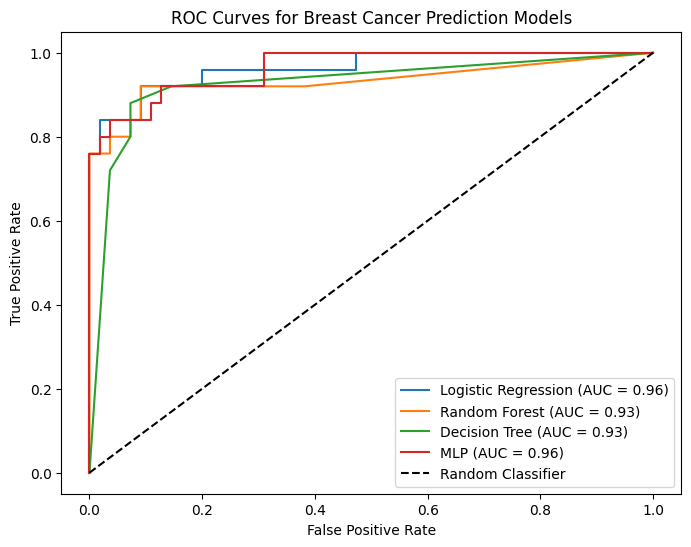

In [26]:
#Membuat ROC Analisis
def plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp):
    plt.figure(figsize=(8, 6))

    # Calculate ROC curves for each model
    fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_pred_logreg)
    fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)
    fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_dt)
    fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_pred_mlp)

    # Plot ROC curves
    plt.plot(fpr_logreg, tpr_logreg, label=f'Logistic Regression (AUC = {auc_logreg:.2f})')
    plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
    plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {auc_dt:.2f})')
    plt.plot(fpr_mlp, tpr_mlp, label=f'MLP (AUC = {auc_mlp:.2f})')

    # Plot random classifier
    plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

    # Format the plot
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for Breast Cancer Prediction Models')
    plt.legend()
    plt.show()

plot_roc_curves(y_test, y_pred_logreg, y_pred_rf, y_pred_dt, y_pred_mlp)

In [27]:
def find_rates_for_thresholds(y_test, y_pred, thresholds):
    fpr_list = []
    tpr_list = []
    for threshold in thresholds:
        y_pred_binary = (y_pred > threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_binary, labels=[0, 1]).ravel()
        fpr = fp / (fp + tn)
        tpr = tp / (tp + fn)
        fpr_list.append(fpr)
        tpr_list.append(tpr)
    return fpr_list, tpr_list

thresholds = np.arange(0, 1.1, 0.1)

fpr_logreg, tpr_logreg = find_rates_for_thresholds(y_test, y_pred_logreg, thresholds)
fpr_rf, tpr_rf = find_rates_for_thresholds(y_test, y_pred_rf, thresholds)
fpr_dt, tpr_dt = find_rates_for_thresholds(y_test, y_pred_dt, thresholds)
fpr_mlp, tpr_mlp = find_rates_for_thresholds(y_test, y_pred_mlp, thresholds)

# Summary DataFrame
summary_df = pd.DataFrame({'Threshold': thresholds,
                           'FPR LogReg': fpr_logreg, 'TPR LogReg': tpr_logreg,
                           'FPR RF': fpr_rf, 'TPR RF': tpr_rf,
                           'FPR DT': fpr_dt, 'TPR DT': tpr_dt,
                           'FPR MLP': fpr_mlp, 'TPR MLP': tpr_mlp})

print(summary_df)

    Threshold  FPR LogReg  TPR LogReg    FPR RF  TPR RF    FPR DT  TPR DT  \
0         0.0    1.000000        1.00  0.381818    0.92  0.145455    0.92   
1         0.1    0.090909        0.92  0.163636    0.92  0.072727    0.88   
2         0.2    0.090909        0.84  0.127273    0.92  0.072727    0.88   
3         0.3    0.072727        0.84  0.109091    0.92  0.072727    0.80   
4         0.4    0.036364        0.84  0.072727    0.80  0.072727    0.80   
5         0.5    0.018182        0.84  0.036364    0.80  0.072727    0.80   
6         0.6    0.018182        0.80  0.036364    0.76  0.072727    0.80   
7         0.7    0.000000        0.76  0.000000    0.72  0.072727    0.80   
8         0.8    0.000000        0.76  0.000000    0.68  0.036364    0.72   
9         0.9    0.000000        0.76  0.000000    0.68  0.036364    0.72   
10        1.0    0.000000        0.00  0.000000    0.00  0.000000    0.00   

     FPR MLP  TPR MLP  
0   1.000000     1.00  
1   0.072727     0.84  
2  

In [28]:
def find_best_threshold(y_test, y_pred):
    # based on Youden's Index
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    optimal_idx = np.argmax(tpr - fpr)
    return thresholds[optimal_idx]

best_threshold_logreg = find_best_threshold(y_test, y_pred_logreg)
best_threshold_rf = find_best_threshold(y_test, y_pred_rf)
best_threshold_dt = find_best_threshold(y_test, y_pred_dt)
best_threshold_mlp = find_best_threshold(y_test, y_pred_mlp)

print(f"Best threshold for Logistic Regression: {best_threshold_logreg}")
print(f"Best threshold for Random Forest: {best_threshold_rf}")
print(f"Best threshold for Decision Tree: {best_threshold_dt}")
print(f"Best threshold for MLP: {best_threshold_mlp}")

Best threshold for Logistic Regression: 0.13099079444292808
Best threshold for Random Forest: 0.3136770651039268
Best threshold for Decision Tree: 0.25
Best threshold for MLP: 0.3500388381312378


**Ingat**

1. Jika kita menginginkan model yang memiliki sensitivitas yang tinggi, yaitu kemampuan untuk mendeteksi sebanyak mungkin kasus positif (True Positive), maka lebih baik menggunakan treshold yang lebih rendah. Namun, ini mungkin juga akan menyebabkan peningkatan False Positive Rate (kasus negatif yang salah diprediksi positif).
2. Sebaliknya, jika kita ingin mengurangi kesalahan dalam memprediksi kasus negatif sebagai positif (False Positive), maka kita akan memilih treshold yang lebih tinggi. Namun, ini dapat mengurangi sensitivitas model.

[Tulis kesimpulan: model terbaik berdasarkan akurasi, AUC-ROC, dan threshold terbaiknya.]

In [29]:
import pickle
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Memilih model terbaik berdasarkan AUC-ROC
hasil = {'Logistic Regression': (auc_logreg, fit_clf_lg),
         'Random Forest': (auc_rf, fit_clf_rf),
         'Decision Tree': (auc_dt, fit_clf_dt),
         'MLP': (auc_mlp, fit_clf_mlp)}
nama_terbaik = max(hasil, key=lambda k: hasil[k][0])
print("Model terbaik:", nama_terbaik, "dengan AUC =", hasil[nama_terbaik][0])

# Pipeline (scaler + model terbaik) dilatih ulang pada data asli, agar aplikasi Streamlit
# bisa langsung menerima input mentah tanpa scaling manual
model_terbaik = Pipeline([('scaler', StandardScaler()),
                          ('model', clone(hasil[nama_terbaik][1].best_estimator_))])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
model_terbaik.fit(Xtr, ytr)
print("Akurasi pipeline pada data uji:", accuracy_score(yte, model_terbaik.predict(Xte)))

# Menyimpan model terbaik dengan pickle
pklname = "generate_breast_cancer.pkl"

with open(pklname, 'wb') as file:  
    pickle.dump(model_terbaik, file)
print("Fitur yang dipakai (urutan harus sama di aplikasi):", X.columns.tolist())

Model terbaik: Logistic Regression dengan AUC = 0.9643636363636364
Akurasi pipeline pada data uji: 0.9375
Fitur yang dipakai (urutan harus sama di aplikasi): ['area_worst', 'perimeter_worst', 'radius_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'area_se', 'area_mean', 'perimeter_mean']
